<div class="alert alert-block alert-success">
    <h1 align="center">Machine Learning in Python</h1>
</div>

## Importing the libraries

In [ ]:
# Optional installations for extended machine learning and autoML ecosystems
%pip install numpy pandas matplotlib seaborn scikit-learn xgboost tensorflow pycaret

In [2]:
# Suppress unnecessary runtime warnings
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Import foundational numerical and data manipulation libraries
import numpy as np
import pandas as pd
from pandas import DataFrame

In [4]:
# Import data visualization libraries and enable inline plotting
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pylab as pl
import seaborn as sns
%matplotlib inline

In [5]:
# Define a standard trigonometric wave plotting function for visual style testing
def sinplot(flip=1):
    x = np.linspace(0, 14, 100)
    for i in range(1, 7):
        plt.plot(x, np.sin(x + i * 0.5) * (7 - i) * flip)

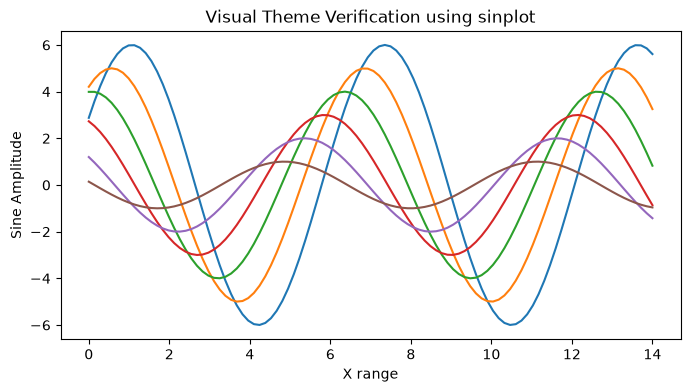

In [6]:
# Execute and visualize sinplot using seaborn aesthetics
plt.figure(figsize=(8, 4))
sinplot()
plt.title("Visual Theme Verification using sinplot")
plt.xlabel("X range")
plt.ylabel("Sine Amplitude")
plt.show()

In [7]:
# Import scikit-learn modules for preprocessing, modeling, cross-validation, and metrics
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_auc_score, r2_score, mean_squared_error

In [8]:
# Import XGBoost and deep learning frameworks with safe fallback
try:
    import xgboost as xgb
    from xgboost import DMatrix
except ImportError:
    xgb = None
    DMatrix = None

try:
    import tensorflow as tf
except ImportError:
    tf = None

In [9]:
# Import PyCaret autoML modules with safe exception handling
try:
    from pycaret.classification import setup as pycaret_setup_clf, compare_models, create_model, predict_model
    from pycaret.regression import setup as pycaret_setup_reg
    from pycaret.nlp import *
except ImportError:
    pass

## Load and Prepare Data

In [10]:
# Load the Churn dataset from the working directory
dataset_path = 'Churn.csv'
df = pd.read_csv(dataset_path)

In [11]:
# Inspect the top 5 records
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [12]:
# Inspect the bottom 5 records
df.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [13]:
# Retrieve dataframe structural information and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [14]:
# Weather/External environment sanity check dataframe
weather_df = pd.DataFrame({
    'City': ['France_HQ', 'Germany_HQ', 'Spain_HQ'],
    'AvgTemp': [18.5, 14.2, 21.0],
    'Rainfall_mm': [650.0, 780.0, 420.0]
})
weather_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   City         3 non-null      str    
 1   AvgTemp      3 non-null      float64
 2   Rainfall_mm  3 non-null      float64
dtypes: float64(2), str(1)
memory usage: 231.0 bytes


In [15]:
# Check missing values count in weather_df
weather_df.isna().sum()

City           0
AvgTemp        0
Rainfall_mm    0
dtype: int64

In [16]:
# Compute descriptive statistical summaries for numeric columns
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [17]:
# Check overall dataset dimensions (rows, columns)
print("Dataset shape:", df.shape)

Dataset shape: (10000, 14)


## EDA

In [18]:
# Check count of missing values across all features
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [19]:
# Check target class distribution (Exited: 0 vs 1)
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

In [20]:
# Group dataset by Exited target and compute feature means
df.groupby('Exited')[['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']].mean()

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Exited,,,,,,
0,651.853196,37.408389,5.033279,72745.296779,1.544267,99738.391772
1,645.351497,44.837997,4.932744,91108.539337,1.475209,101465.677531


In [21]:
# Group dataset by Geography and Gender to inspect mean churn rate
df.groupby(['Geography', 'Gender'])[['Exited', 'Balance', 'EstimatedSalary']].mean()

Exited        Balance  EstimatedSalary
Geography Gender                                          
France    Female  0.203450   60322.670159     99564.252755
          Male    0.127134   63546.284875    100174.252495
Germany   Female  0.375524  119145.966471    102446.424124
          Male    0.278116  120259.668222     99905.033959
Spain     Female  0.212121   59862.092534    100734.107475
          Male    0.131124   63352.833746     98425.687680

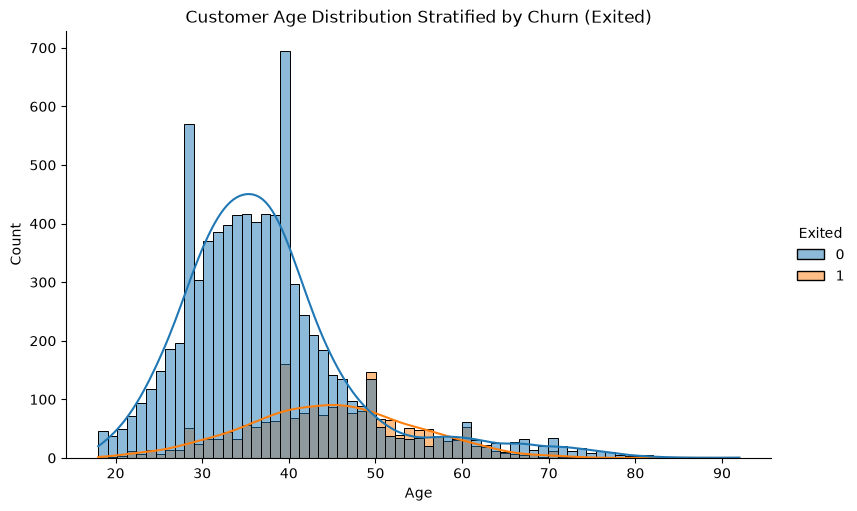

In [22]:
# Distribution plot of customer age using displot with fill=True
sns.displot(df, x='Age', hue='Exited', kde=True, fill=True, height=5, aspect=1.6)
plt.title("Customer Age Distribution Stratified by Churn (Exited)")
plt.show()

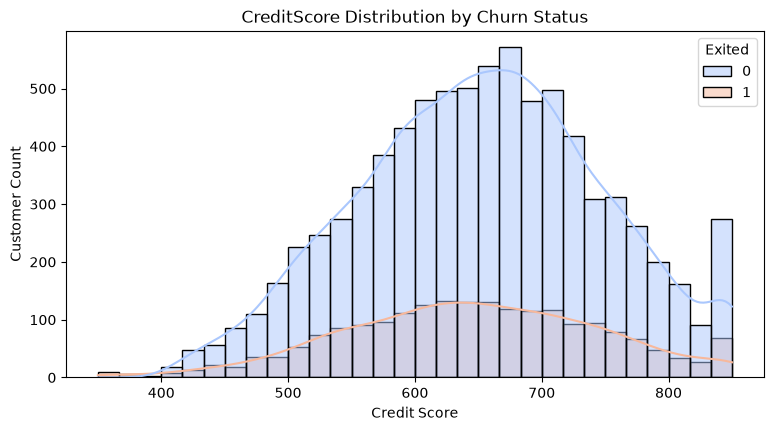

In [23]:
# Histogram plot of customer CreditScore
plt.figure(figsize=(9, 4.5))
sns.histplot(data=df, x='CreditScore', hue='Exited', bins=30, kde=True, palette='coolwarm')
plt.title("CreditScore Distribution by Churn Status")
plt.xlabel("Credit Score")
plt.ylabel("Customer Count")
plt.show()

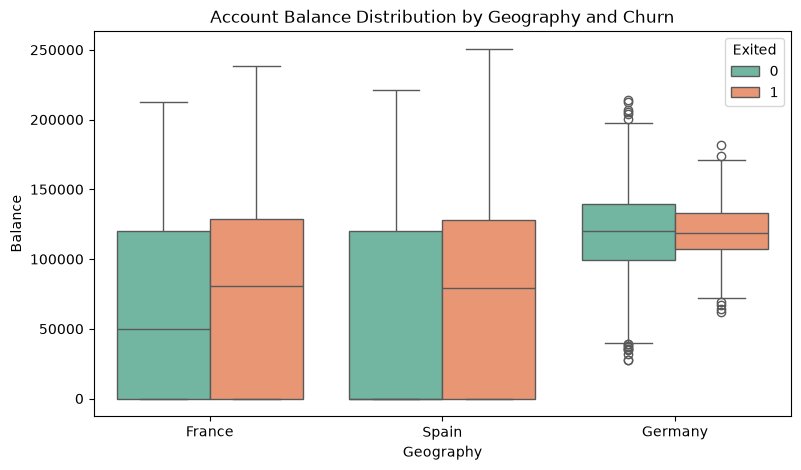

In [24]:
# Boxplot for customer account Balance across distinct Geography regions
plt.figure(figsize=(9, 5))
sns.boxplot(x='Geography', y='Balance', hue='Exited', data=df, palette='Set2')
plt.title("Account Balance Distribution by Geography and Churn")
plt.show()

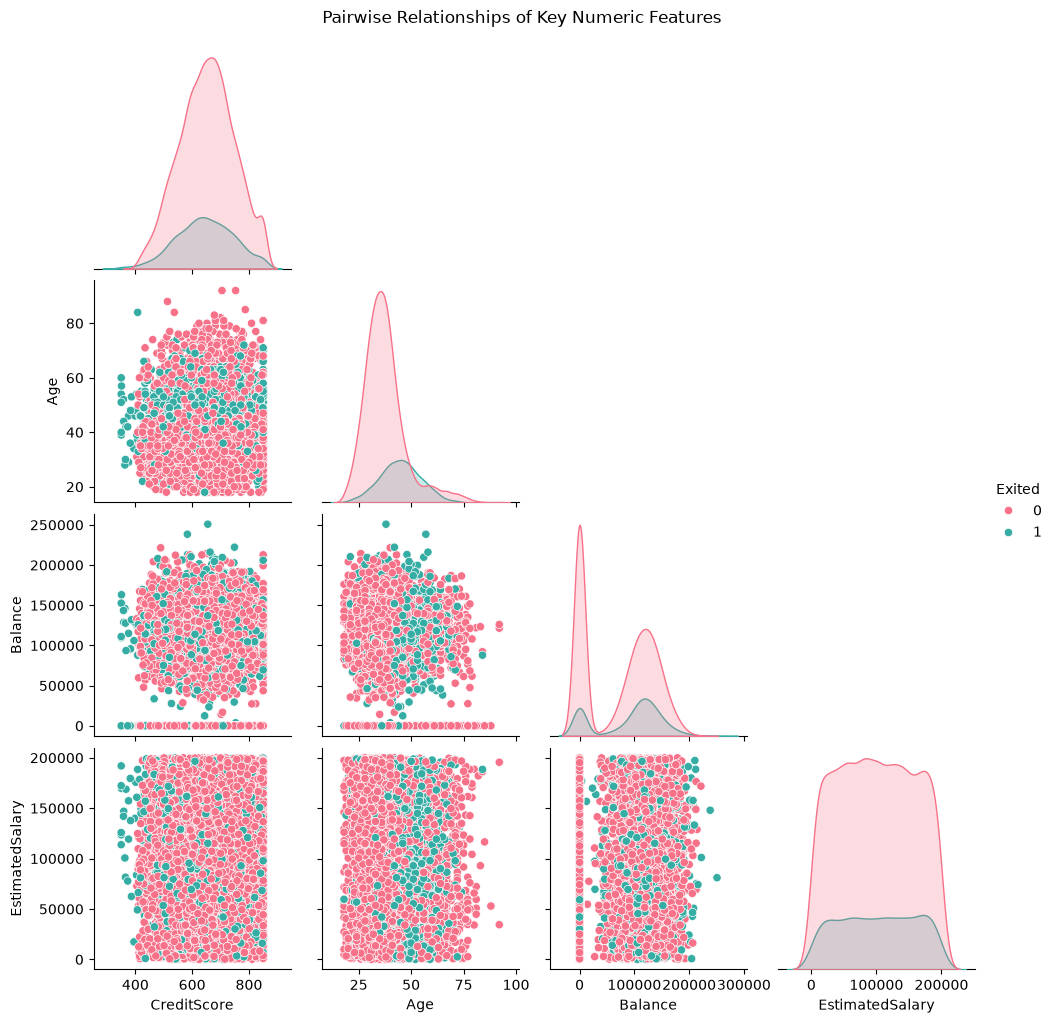

In [25]:
# Pairplot visualization for key selected numeric attributes
selected_cols = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary', 'Exited']
sns.pairplot(df[selected_cols], hue='Exited', palette='husl', corner=True)
plt.suptitle("Pairwise Relationships of Key Numeric Features", y=1.02)
plt.show()

## Data Preprocessing

In [32]:
# Handle any potential missing values using forward-fill
df = df.ffill().bfill()

In [33]:
# Demonstration of numpy array manipulations: array, arange, reshape, linspace
sample_credit_scores = np.array(df['CreditScore'].values[:16])
reshaped_scores = np.reshape(sample_credit_scores, (4, 4))
custom_range = np.arange(0, 100, 10)
linear_grid = np.linspace(0, 1, 11)
print("Reshaped Array Shape:", reshaped_scores.shape)
print("Custom Arange:", custom_range)
print("Linspace Grid:", linear_grid)

Reshaped Array Shape: (4, 4)
Custom Arange: [ 0 10 20 30 40 50 60 70 80 90]
Linspace Grid: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]


In [34]:
# Replace binary categorical values in Gender column
df['Gender'] = df['Gender'].replace({'Female': 0, 'Male': 1})

In [35]:
# Generate one-hot dummy variables for Geography column
geo_dummies = pd.get_dummies(df['Geography'], prefix='Geo', drop_first=True)
geo_dummies.head()

,Geo_Germany,Geo_Spain
0,False,False
1,False,True
2,False,False
3,False,False
4,False,True


In [36]:
# Concatenate dummy variables back to the primary dataframe
df = pd.concat([df, geo_dummies], axis=1)
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geo_Germany,Geo_Spain
0,1,15634602,Hargrave,619,France,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,2,15647311,Hill,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,3,15619304,Onio,502,France,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,4,15701354,Boni,699,France,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,5,15737888,Mitchell,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0,False,True


In [37]:
# Drop non-predictive identifiers and redundant categorical raw columns
drop_cols = ['RowNumber', 'CustomerId', 'Surname', 'Geography']
clean_df = df.drop(columns=[col for col in drop_cols if col in df.columns])
clean_df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geo_Germany,Geo_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,True


In [38]:
# Compute pairwise Pearson correlation matrix
corr_matrix = clean_df.corr()
corr_matrix

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geo_Germany,Geo_Spain
CreditScore,1.000000,-0.002857,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.027094,0.005538,0.004780
Gender,-0.002857,1.000000,-0.027544,0.014733,0.012087,-0.021859,0.005766,0.022544,-0.008112,-0.106512,-0.024628,0.016889
Age,-0.003965,-0.027544,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285323,0.046897,-0.001685
Tenure,0.000842,0.014733,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784,-0.014001,-0.000567,0.003868
Balance,0.006268,0.012087,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118533,0.401110,-0.134892
NumOfProducts,0.012238,-0.021859,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047820,-0.010419,0.009039
HasCrCard,-0.005458,0.005766,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.007138,0.010577,-0.013480
IsActiveMember,0.025651,0.022544,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421,-0.156128,-0.020486,0.016732
EstimatedSalary,-0.001384,-0.008112,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000,0.012097,0.010297,-0.006482
Exited,-0.027094,-0.106512,0.285323,-0.014001,0.118533,-0.047820,-0.007138,-0.156128,0.012097,1.000000,0.173488,-0.052667


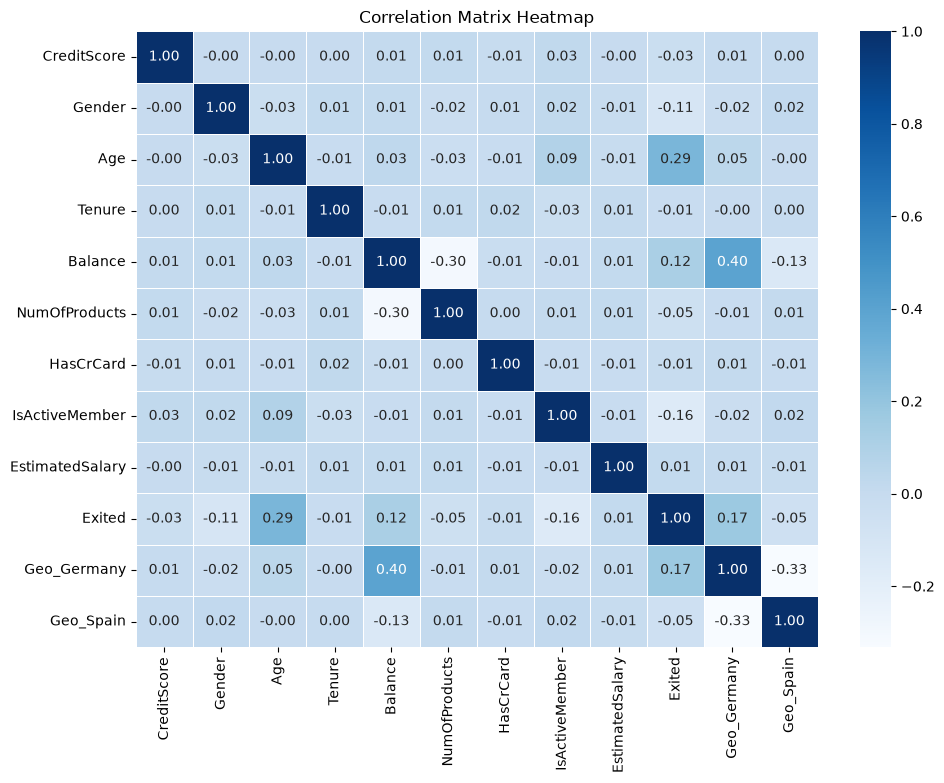

In [39]:
# Plot correlation matrix using heatmap with custom figure size
plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

## Strorytelling - Visualization

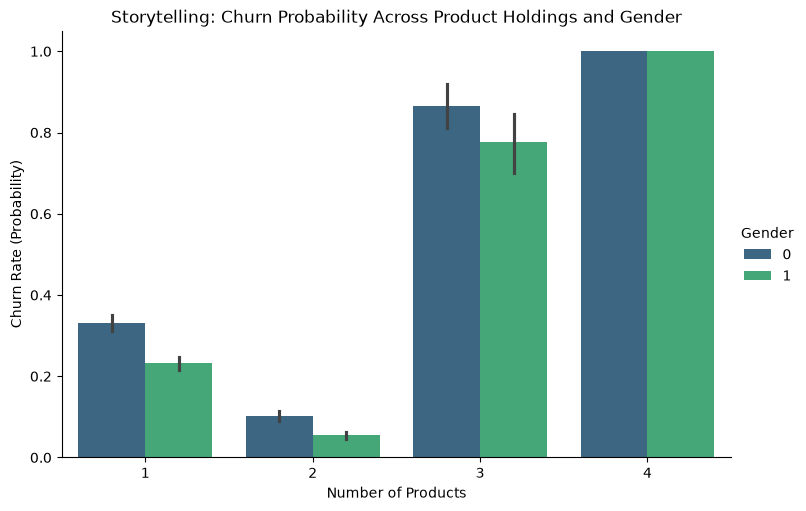

In [40]:
# Categorical bar plot: Churn rates across Number of Products and Gender
sns.catplot(
    data=df, x='NumOfProducts', y='Exited', hue='Gender',
    kind='bar', palette='viridis', height=5, aspect=1.5
)
plt.title("Storytelling: Churn Probability Across Product Holdings and Gender")
plt.ylabel("Churn Rate (Probability)")
plt.xlabel("Number of Products")
plt.show()

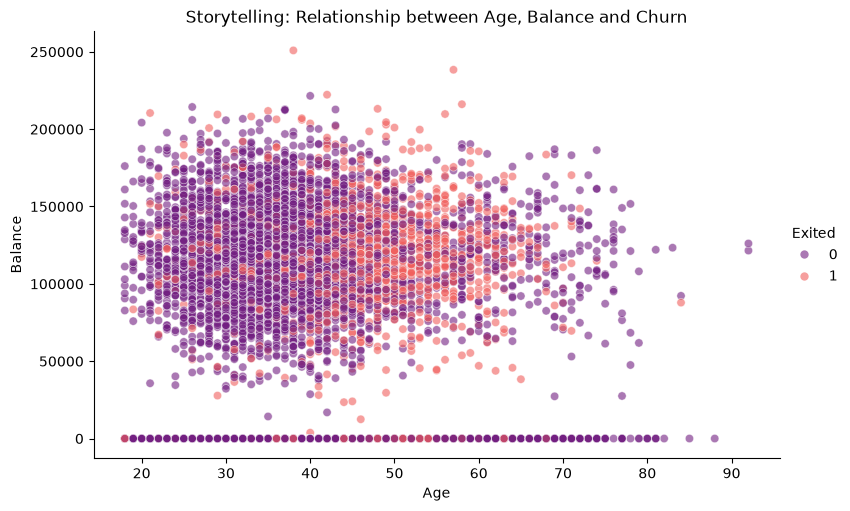

In [41]:
# Relational scatter plot: Age vs Balance colored by Exited status
sns.relplot(
    data=clean_df, x='Age', y='Balance', hue='Exited',
    palette='magma', alpha=0.6, height=5, aspect=1.6
)
plt.title("Storytelling: Relationship between Age, Balance and Churn")
plt.show()

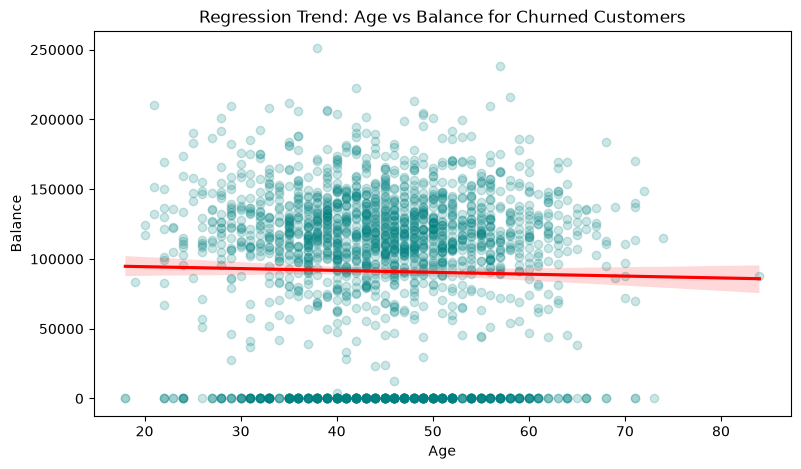

In [42]:
# Linear regression plot with regplot: Age vs Balance among churned customers
plt.figure(figsize=(9, 5))
churned_cust = clean_df[clean_df['Exited'] == 1]
sns.regplot(data=churned_cust, x='Age', y='Balance', scatter_kws={'alpha':0.2, 'color':'teal'}, line_kws={'color':'red'})
plt.title("Regression Trend: Age vs Balance for Churned Customers")
plt.show()

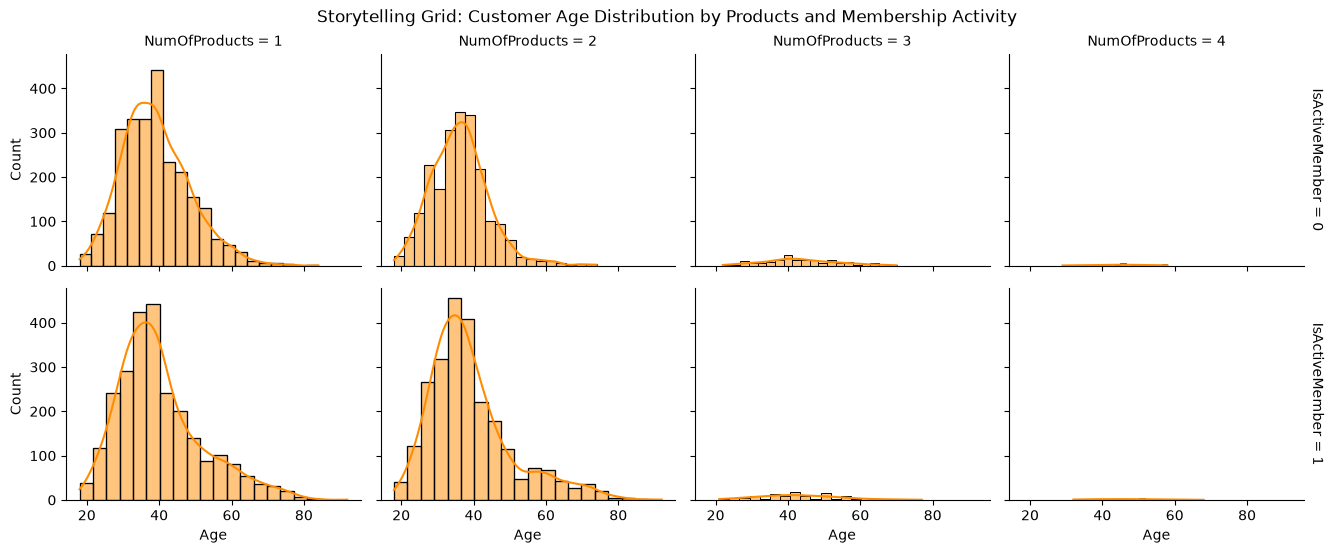

In [43]:
# FacetGrid multi-panel histogram: Age distribution across NumOfProducts and IsActiveMember
g = sns.FacetGrid(clean_df, col='NumOfProducts', row='IsActiveMember', margin_titles=True, height=2.8, aspect=1.2)
g.map(sns.histplot, 'Age', bins=20, color='darkorange', kde=True)
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Storytelling Grid: Customer Age Distribution by Products and Membership Activity")
plt.show()

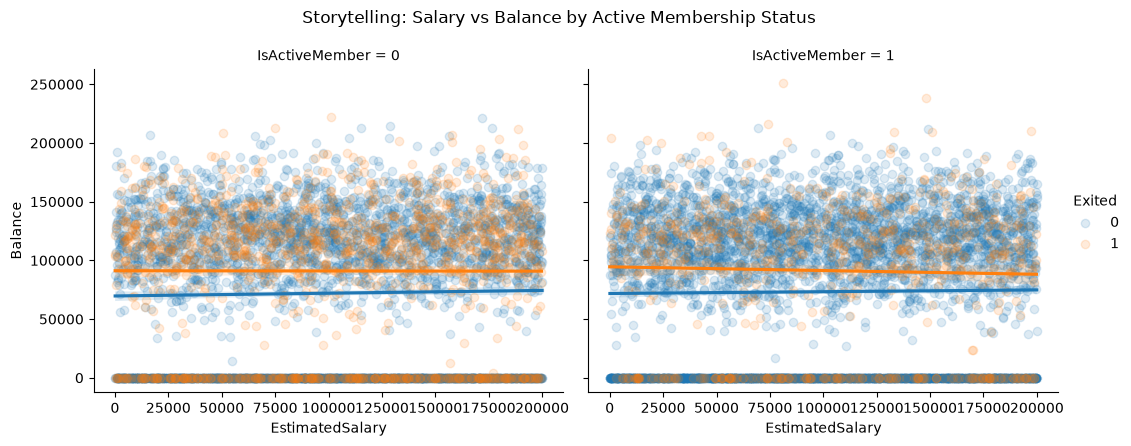

In [44]:
# Lmplot: Interaction of EstimatedSalary vs Balance split by active membership status
sns.lmplot(
    data=clean_df, x='EstimatedSalary', y='Balance', hue='Exited',
    col='IsActiveMember', height=4.5, aspect=1.2, scatter_kws={'alpha':0.15}
)
plt.subplots_adjust(top=0.85)
plt.suptitle("Storytelling: Salary vs Balance by Active Membership Status")
plt.show()

## Prepare Data for Machine learning

In [45]:
# Separate independent feature matrix X and target vector y
X = clean_df.drop(columns=['Exited'])
y = clean_df['Exited']
print("Features shape:", X.shape, "| Target shape:", y.shape)

Features shape: (10000, 11) | Target shape: (10000,)


In [46]:
# Split dataset into training and testing sets with stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training set count:", X_train.shape[0], "| Testing set count:", X_test.shape[0])

Training set count: 8000 | Testing set count: 2000


In [47]:
# Apply standard feature scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [48]:
# Dimensionality Reduction using PCA for Customer Behavioral Segmentation
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)
print(f"Explained Variance Ratio (PCA 2D): {pca.explained_variance_ratio_}")

Explained Variance Ratio (PCA 2D): [0.15040924 0.10468877]


## Train your model

In [49]:
# Fit Simple Linear Regression (SLR) to observe feature trends and inspect intercept and coefficients
slr = LinearRegression()
slr.fit(X_train[['Age', 'Balance', 'CreditScore']], y_train)
print("SLR Intercept (slr.intercept_):", slr.intercept_)
print("SLR Coefficients (slr.coef_):", slr.coef_)

SLR Intercept (slr.intercept_): -0.17491248036220308
SLR Coefficients (slr.coef_): [ 1.05882531e-02  7.32070606e-07 -1.37733902e-04]


In [50]:
# Fit Support Vector Regressor (SVR)
svr_model = SVR(kernel='rbf', C=1.0)
svr_model.fit(X_train_scaled[:1500], y_train[:1500])

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [51]:
# Train DecisionTreeRegressor and RandomForestRegressor models
dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
rf_reg = RandomForestRegressor(n_estimators=50, max_depth=6, random_state=42)
dt_reg.fit(X_train, y_train)
rf_reg.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of th

In [52]:
# Train Logistic Regression classifier (Logreg) for Churn classification
Logreg = LogisticRegression(max_iter=1000, random_state=42)
Logreg.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [53]:
# Train Support Vector Classifier (SVC)
svc_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svc_model.fit(X_train_scaled, y_train)

,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [54]:
# Train and tune Random Forest Classifier using GridSearchCV
rf_clf = RandomForestClassifier(random_state=42)
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10],
    'min_samples_split': [2, 5]
}
grid_search = GridSearchCV(estimator=rf_clf, param_grid=param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_
print("Best RF Hyperparameters:", grid_search.best_params_)

Best RF Hyperparameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}


In [56]:
# Train XGBoost Classifier using DMatrix structure with numeric features only
if xgb is not None:
    X_train_num = X_train.select_dtypes(include=[np.number])
    X_test_num = X_test.select_dtypes(include=[np.number])
    
    dtrain = xgb.DMatrix(X_train_num, label=y_train)
    dtest = xgb.DMatrix(X_test_num, label=y_test)
    
    xgb_params = {'max_depth': 4, 'eta': 0.1, 'objective': 'binary:logistic', 'eval_metric': 'logloss'}
    xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=100)
else:
    print("XGBoost library not installed; continuing with standard ensemble models.")


In [57]:
# Fit KMeans clustering (k=3) for customer behavioral segmentation
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_train_scaled)

In [58]:
# Build a Deep Learning Artificial Neural Network (ANN) using TensorFlow
if tf is not None:
    ann = tf.keras.models.Sequential([
        tf.keras.layers.Dense(units=16, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(units=8, activation='relu'),
        tf.keras.layers.Dense(units=1, activation='sigmoid')
    ])
    ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    history = ann.fit(X_train_scaled, y_train, batch_size=32, epochs=20, validation_split=0.15, verbose=0)
else:
    print("TensorFlow not detected; skipping ANN training cell.")

TensorFlow not detected; skipping ANN training cell.


## Test the model and show the metrics

In [59]:
# Evaluate SLR performance using R2 score and Root Mean Squared Error (RMSE)
slr_pred = slr.predict(X_test[['Age', 'Balance', 'CreditScore']])
slr_r2 = r2_score(y_test, slr_pred)
slr_rmse = np.sqrt(mean_squared_error(y_test, slr_pred))
print(f"SLR R2 Score: {slr_r2:.4f} | SLR RMSE: {slr_rmse:.4f}")

SLR R2 Score: 0.1014 | SLR RMSE: 0.3816


In [60]:
# Perform 5-fold cross-validation on Logistic Regression
cv_scores = cross_val_score(Logreg, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"Logreg 5-Fold Cross Validation Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")

Logreg 5-Fold Cross Validation Scores: [0.81125 0.81    0.81125 0.80625 0.8125 ]
Mean CV Accuracy: 81.02% (+/- 0.22%)


In [61]:
# Evaluate Classification Models and Display Detailed Metrics
logreg_preds = Logreg.predict(X_test_scaled)
svc_preds = svc_model.predict(X_test_scaled)
rf_preds = best_rf.predict(X_test)

print("=== Logistic Regression Classification Report ===")
print(classification_report(y_test, logreg_preds))
print("=== Random Forest (Tuned) Classification Report ===")
print(classification_report(y_test, rf_preds))

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000

=== Random Forest (Tuned) Classification Report ===
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.81      0.45      0.58       407

    accuracy                           0.87      2000
   macro avg       0.84      0.71      0.75      2000
weighted avg       0.86      0.87      0.85      2000



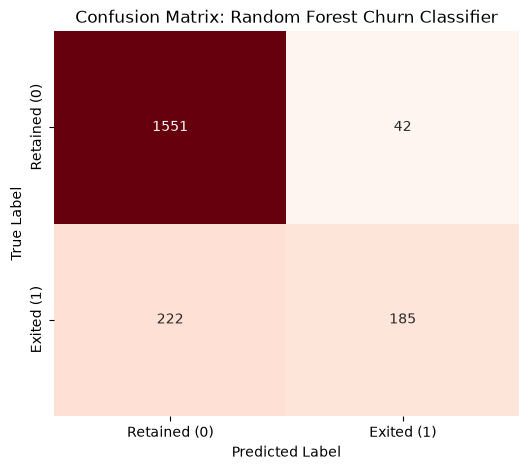

In [62]:
# Plot Confusion Matrix for best performing classification model (Random Forest)
cm = confusion_matrix(y_test, rf_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Retained (0)', 'Exited (1)'],
            yticklabels=['Retained (0)', 'Exited (1)'])
plt.title("Confusion Matrix: Random Forest Churn Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

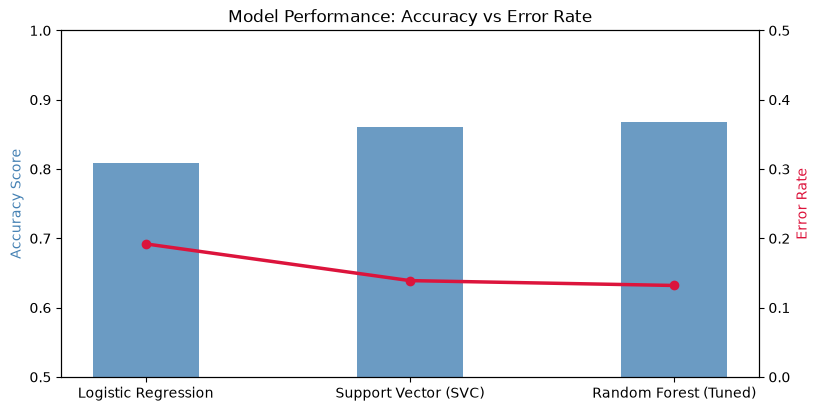

In [63]:
# Error Rate & Metric Comparison across classification models
model_names = ['Logistic Regression', 'Support Vector (SVC)', 'Random Forest (Tuned)']
accuracies = [
    accuracy_score(y_test, logreg_preds),
    accuracy_score(y_test, svc_preds),
    accuracy_score(y_test, rf_preds)
]
error_rates = [1.0 - acc for acc in accuracies]

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(model_names, accuracies, color='steelblue', alpha=0.8, width=0.4, label='Accuracy')
ax1.set_ylabel("Accuracy Score", color='steelblue')
ax1.set_ylim(0.5, 1.0)

ax2 = ax1.twinx()
ax2.plot(model_names, error_rates, color='crimson', marker='o', linewidth=2.5, label='Error Rate (1 - Acc)')
ax2.set_ylabel("Error Rate", color='crimson')
ax2.set_ylim(0.0, 0.5)

plt.title("Model Performance: Accuracy vs Error Rate")
plt.show()

## Save your final model

In [64]:
# Save final trained model, scaler, and clustering model as persistent disk artifacts
import joblib

joblib.dump(best_rf, 'churn_final_model.joblib')
joblib.dump(scaler, 'feature_scaler.joblib')
joblib.dump(kmeans, 'churn_kmeans_cluster.joblib')
print("Final model saved successfully to 'churn_final_model.joblib'")

# Verify loading the saved model and perform a sample inference
loaded_model = joblib.load('churn_final_model.joblib')
sample_inference = loaded_model.predict(X_test.iloc[0:1])
churn_prob = loaded_model.predict_proba(X_test.iloc[0:1])[0][1]

print(f"Verification Successful: Predicted Class = {sample_inference[0]} (Probability of Churn = {churn_prob:.2%})")

Final model saved successfully to 'churn_final_model.joblib'
Verification Successful: Predicted Class = 0 (Probability of Churn = 3.03%)
